# **ROTATING EQUIPMENT ANOMALY DETECTION**
During the Anomaly Detection phase, the algorithm identifies samples in data set which differ from the normal
operation condition.
We worked on data collected by ENI on rotating machines.


In [108]:
# All machines: V470MT001A (Old+New),  V360KB011E(Old+new), V360KB011B (New) 
MACHINE_NAME = "V360KB011E"

In [115]:
import sys
import numpy as np
import pandas as pd
from datetime import datetime
from sklearn.preprocessing import StandardScaler


def consider_range(noc_data, sensor_data):
    ''' 1. creation of the sensor data training filtering the intervals present in noc data '''
    sensor_data_training = pd.DataFrame()
    sensor_data['sensor_ts'] = pd.to_datetime(sensor_data['sensor_ts'], format='%Y-%m-%d %H:%M:%S')
    for  a in noc_data[['range_start', 'range_end']].values:
        range_str = (a[0], a[1])
        sensor_data_temp = sensor_data[(sensor_data['sensor_ts'] >= datetime.strptime(range_str[0], "%Y-%m-%d %H:%M:%S")) & (sensor_data['sensor_ts'] <= datetime.strptime(range_str[1], "%Y-%m-%d %H:%M:%S"))]
        sensor_data_training = pd.concat([sensor_data_training, sensor_data_temp])
    return sensor_data_training


def add_labels(sensor_data, sensor_data_training, labels='NOC'):
    sensor_data[labels] = 0
    sensor_data.loc[sensor_data['sensor_ts'].isin(sensor_data_training['sensor_ts']), labels] = 1
    return sensor_data


def cut_col(train_card):
    ''' cut columns from G to J and column tag_id'''
    train_card = train_card.drop(columns = [*train_card.columns[6:10], 'tag_id'])
    return train_card


def import_datasets(name_machine, IN_COLAB):
    '''Import required datasets. It depends on the machine considered'''
    dataset_folder_old = dataset_folder_new = dataset_folder = ""

    if name_machine == 'V470MT001A':
        if IN_COLAB:
          # old data
          dataset_folder_old = f"/content/drive/MyDrive/AI_Industry_Data/old_data/train_V470MT001A_idtraining_889/"
          # new data
          dataset_folder_new = f"/content/drive/MyDrive/AI_Industry_Data/new_data/V470MT001A/"

        # old data
        noc_data_old = pd.read_csv(dataset_folder_old + f"noc_data_{name_machine}_889.csv",sep=",")
        sensor_data_old = pd.read_csv(dataset_folder_old + f"sensor_data_{name_machine}_889.csv",sep=",")
        sensor_data_old.drop(['COVA.ABB.V470-A018-A.pv', 'COVA.ABB.V470-A028-A.pv'], axis=1, inplace=True) # removing two sensors beacuse thery're missing in new data
        train_card = pd.read_csv(dataset_folder_old + f"train_card_{name_machine}_889.csv",sep=",")

        # new data
        confirmed_anomalies_new = pd.read_excel(dataset_folder_new + f"MT001A_confirmed_anomalies.xlsx")
        sensor_data_new = pd.read_csv(dataset_folder_new + f"MT001A_sensorsdata_new.csv", sep=",")
        confirmed_anomalies_new.rename(columns={'anomaly_start': 'range_start', 'anomaly_end': 'range_end'}, inplace=True)
        confirmed_anomalies_new["range_start"] = confirmed_anomalies_new.apply(lambda x : str(x["range_start"]),axis=1)
        confirmed_anomalies_new["range_end"] = confirmed_anomalies_new.apply(lambda x : str(x["range_end"]),axis=1)

        # Cols to consider
        target_cols = list(set(sensor_data_old.columns) & set(sensor_data_new.columns)) # since the old and the new data have some columns that dont match, we consider only the common columns
        sensor_data_old = sensor_data_old[target_cols]
        sensor_data_new = sensor_data_new[target_cols]
        target_cols.remove('sensor_ts')

        # casting time stamps
        sensor_data_new["sensor_ts"] = sensor_data_new.apply(lambda x : x["sensor_ts"].replace("T", " ")[:-6],axis=1)

        # adding NOC label based on NOC intervals - old data
        sensor_data_training = consider_range(noc_data_old, sensor_data_old)
        sensor_data_old = add_labels(sensor_data_old, sensor_data_training, labels = 'NOC')
        # columns reordering
        sensor_data_old = sensor_data_old.loc[:, ['sensor_ts'] + target_cols + ['NOC']]
        # adding anomaly label based on anomaly intervals - new data
        sensor_data_testing = consider_range(confirmed_anomalies_new, sensor_data_new)
        sensor_data_new = add_labels(sensor_data_new, sensor_data_testing, labels='anomaly')
        # columns reordering
        sensor_data_new = sensor_data_new.loc[:, ['sensor_ts'] + target_cols + ['anomaly']]

    if name_machine == 'V360KB011E':
        if IN_COLAB:
          # old data
          dataset_folder_old = f"/content/drive/MyDrive/AI_Industry_Data/old_data/train_V360KB011E_idtraining_849/"
          # new data
          dataset_folder_new = f"/content/drive/MyDrive/AI_Industry_Data/new_data/V360KB11E/"

        # old data
        noc_data_old = pd.read_csv(dataset_folder_old + f"noc_data_{name_machine}_849.csv", sep=",")
        sensor_data_old = pd.read_csv(dataset_folder_old + f"sensor_data_{name_machine}_849.csv", sep=",")
        train_card = pd.read_csv(dataset_folder_old + f"train_card_{name_machine}_849.csv", sep=",")

        # new data
        confirmed_anomalies_new = pd.read_excel(dataset_folder_new + f"11E_confirmed_anomalies.xlsx")
        sensor_data_new = pd.read_csv(dataset_folder_new + f"11E_sensorsdata_new.csv", sep=",")
        confirmed_anomalies_new.rename(columns={'anomaly_start': 'range_start', 'anomaly_end': 'range_end'}, inplace=True)
        confirmed_anomalies_new["range_start"] = confirmed_anomalies_new.apply(lambda x: str(x["range_start"]), axis=1)
        confirmed_anomalies_new["range_end"] = confirmed_anomalies_new.apply(lambda x: str(x["range_end"]), axis=1)

        # Cols to consider
        target_cols = list(set(sensor_data_old.columns) & set(
            sensor_data_new.columns))  # since the old and the new data have some columns that dont match, we consider only the common columns
        sensor_data_old = sensor_data_old[target_cols]
        sensor_data_new = sensor_data_new[target_cols]
        target_cols.remove('sensor_ts')

        # casting time stamps
        sensor_data_new["sensor_ts"] = sensor_data_new.apply(lambda x: x["sensor_ts"].replace("T", " ")[:-6],
                                                             axis=1)

        # adding NOC label based on NOC intervals - old data
        sensor_data_noc = consider_range(noc_data_old, sensor_data_old)
        sensor_data_old = add_labels(sensor_data_old, sensor_data_noc, labels='NOC')
        # columns reordering
        sensor_data_old = sensor_data_old.loc[:, ['sensor_ts'] + target_cols + ['NOC']]
        # adding anomaly label based on anomaly intervals - new data
        sensor_data_anomalies = consider_range(confirmed_anomalies_new, sensor_data_new)
        sensor_data_new = add_labels(sensor_data_new, sensor_data_anomalies, labels='anomaly')
        # columns reordering
        sensor_data_new = sensor_data_new.loc[:, ['sensor_ts'] + target_cols + ['anomaly']]

    if name_machine == 'V360KB011B':

        if IN_COLAB:
            dataset_folder = f"/content/drive/MyDrive/AI_Industry_Data/new_data/V360KB011B/"  # CHANGE HERE THE DATA FOLDER

        noc_data = pd.read_csv(dataset_folder + f"noc_data_{name_machine}_111.csv", sep=";")
        sensor_data_new = pd.read_csv(dataset_folder + f"11B_sensorsdata_new.csv", sep=",")
        train_card = pd.read_csv(dataset_folder + f"train_card_{name_machine}_111.csv", sep=";")
        confirmed_anomalies = pd.read_excel(dataset_folder + f"11B_confirmed_anomalies.xlsx")
        confirmed_anomalies.rename(columns={'anomaly_start': 'range_start', 'anomaly_end': 'range_end'}, inplace=True)
        confirmed_anomalies["range_start"] = confirmed_anomalies.apply(lambda x: str(x["range_start"]), axis=1)
        confirmed_anomalies["range_end"] = confirmed_anomalies.apply(lambda x: str(x["range_end"]), axis=1)

        # Cols to consider
        target_cols = sensor_data_new.columns[1:]

        # casting time stamps
        sensor_data_new["sensor_ts"] = sensor_data_new.apply(lambda x: x["sensor_ts"].replace("T", " ")[:-6],
                                                             axis=1)
        # adding NOC label based on NOC intervals - old data
        sensor_data_noc = consider_range(noc_data, sensor_data_new)
        sensor_data_new = add_labels(sensor_data_new, sensor_data_noc, labels='NOC')
        # adding anomaly label based on anomaly intervals - new data
        sensor_data_anomaly = consider_range(confirmed_anomalies, sensor_data_new)
        sensor_data_new = add_labels(sensor_data_new, sensor_data_anomaly, labels='anomaly')
        
        # columns reordering --- Already ordered
        # sensor_data_new = sensor_data_new.loc[:, ['sensor_ts'] + target_cols + ['NOC','anomaly']]

        sensor_data_old = pd.DataFrame(columns=sensor_data_new.columns)

        return noc_data, sensor_data_old, train_card, confirmed_anomalies, sensor_data_new, target_cols

    # eliminate useless colums from train card
    train_card = cut_col(train_card)

    return noc_data_old, sensor_data_old, train_card, confirmed_anomalies_new, sensor_data_new,target_cols


def compute_noc_nnoc_distance(sensor_data, target_cols, target, method='wasserstein', sample_n = 100):
    if not sensor_data.empty:
      distance = None
      if method == 'wasserstein':
          distance = sp.stats.wasserstein_distance_nd(sensor_data[sensor_data[target] == 1][target_cols].sample(sample_n,random_state=42),sensor_data[sensor_data[target] == 0][target_cols].sample(sample_n,random_state=42))
      elif method == 'jensen-shannon':
          distance = sp.spatial.distance.jensenshannon(sensor_data[sensor_data[target] == 1][target_cols].sample(sample_n,random_state=42),sensor_data[sensor_data[target] == 0][target_cols].sample(sample_n,random_state=42))
          distance = pd.Series(distance).replace([np.inf, -np.inf], np.nan).dropna()
          distance = distance.mean()
    else:
      distance = '/'

    return distance

def drop_offline_time_ranges(train_card, sensor_data):
    if not sensor_data.empty:
      data_to_remove = train_card[train_card['onoff_parameter']== 1 ][['boot_threshold','id_sensor']].groupby('id_sensor').first().reset_index()
      for i in range(len(data_to_remove)):
        dtr = data_to_remove.iloc[i]
        sensor_data = sensor_data.drop(np.where(sensor_data[dtr['id_sensor']] <= dtr['boot_threshold'])[0])
    return sensor_data

def drop_nan(sensor_data, target_cols):
    if not sensor_data.empty:
      # Drop columns and rows where all values are NaN
      sensor_data.dropna(axis=0, how='all', subset=target_cols, inplace=True)
      sensor_data.dropna(axis=1, how='all', inplace=True)

      # Drop rows with NaN values
      sensor_data = sensor_data.dropna()

      # Reset the index
      sensor_data.reset_index(drop=True, inplace=True)

    return sensor_data


def scale_data(train_df, test_df):
    # Initialize the StandardScaler
    scaler = StandardScaler()

    if "NOC" in train_df.columns:
      target_train = "NOC"
    else:
      target_train = "anomaly"

    if "NOC" in test_df.columns:
      target_test = "NOC"
    else:
      target_test = "anomaly"

    # TRAIN DATA
    train_data = train_df.drop(['sensor_ts', target_train], axis=1)
    train_ts = train_df['sensor_ts']
    target_train_column = train_df[target_train]
    # Fit the Scaler with train_data
    scaler.fit(train_data)
    # Transform data usign the fitted Scaler
    scaled_train_data = scaler.transform(train_data)
    # Convert the scaled data back to a DataFrame
    scaled_train_data_df = pd.DataFrame(scaled_train_data, index=train_data.index, columns=train_data.columns)
    scaled_train_data_df.insert(0, 'sensor_ts', train_ts)
    scaled_train_data_df[target_train] = target_train_column.values
    # index reset
    scaled_train_data_df = scaled_train_data_df.reset_index(drop = True)

    # TEST DATA
    test_data = test_df.drop(['sensor_ts', target_test], axis=1)
    test_ts = test_df['sensor_ts']
    target_test_column = test_df[target_test]
    # Transform data usign the alredy fitted Scaler
    scaled_test_data = scaler.transform(test_data)
    # Convert the scaled data back to a DataFrame
    scaled_test_data_df = pd.DataFrame(scaled_test_data, index=test_data.index, columns=test_data.columns)
    scaled_test_data_df.insert(0, 'sensor_ts', test_ts)
    scaled_test_data_df[target_test] = target_test_column.values
    # index reset
    scaled_test_data_df = scaled_test_data_df.reset_index(drop = True)

    return scaled_train_data_df, scaled_test_data_df


def plot_columns_in_grid(scaled_train_df, target_cols):
    n_cols = len(target_cols)
    n_rows = n_cols // 3 + (n_cols % 3 > 0)
    fig, axs = plt.subplots(n_rows, 3, figsize=(15, 5 * n_rows))

    for i, col in enumerate(target_cols):
        row = i // 3
        col_idx = i % 3
        axs[row, col_idx].plot(scaled_train_df[col])
        axs[row, col_idx].set_title(col)

    # Hide x labels and tick labels for top plots and y ticks for right plots.
    for ax in axs.flat:
        ax.label_outer()

def train_test_split(sensor_data_old, sensor_data_new, target_cols):
    # Traing and Testing datasets
    if not sensor_data_old.empty and not sensor_data_new.empty:
        train_df = sensor_data_old[sensor_data_old['NOC'] == 1]
        test_df = sensor_data_new
    elif not sensor_data_new.empty:
        train_df = sensor_data_new[sensor_data_new['NOC'] == 1]
        test_df =sensor_data_new[sensor_data_new['NOC'] == 0]
    elif not sensor_data_old.empty:
        train_df = sensor_data_old[int(len(sensor_data_old)*0.8)][sensor_data_old['anomaly'] == 0]
        test_df = pd.concat([sensor_data_old[:int(len(sensor_data_old)*0.8)][sensor_data_old['anomaly'] == 1], sensor_data_old[int(len(sensor_data_old)*0.8):]])


    return train_df, test_df


## Setup

In [93]:
!pip install scikit-optimize
!pip install tqdm
!pip install gdown

### Downloading Models ---------- ***DA MODIFICARE***

In [94]:
try:
  from google.colab import drive
  drive.mount('/content/drive/', force_remount=True)
  IN_COLAB = True
except:
  IN_COLAB = False
if not IN_COLAB:
    #download AE_LSTM
    !gdown --id 1SC5OEYKZ2QOPrvaRCYdYKC3apRDdZbZZ
    #download AE
    !gdown --id 1yNZFDnNUaDPCkITQXSmljk0oFqStjxsu
    #download VAE_LSTM
    !gdown --id 1ybV48nvxzq5jAyPQH6JOPux6SgNRb-_5
    #download VAE
    !gdown --id 1wAAXlv6vvjzJgoexHou1QDHYl8r2fKNG
    #download utils.py
    !gdown --id 1-mZDH0qt7qkf6lHeW9HoVYdkf0MOid-a

if not IN_COLAB:
    !mkdir models
    !mv AE.py models
    !mv AE_LSTM.py models
    !mv VAE.py models
    !mv VAE_LSTM.py models

/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1SC5OEYKZ2QOPrvaRCYdYKC3apRDdZbZZ
From (redirected): https://drive.google.com/uc?id=1SC5OEYKZ2QOPrvaRCYdYKC3apRDdZbZZ&confirm=t&uuid=8e094b16-d243-4226-8bc3-f5d4367c5aa9
To: /kaggle/working/AE_LSTM.py
100%|██████████████████████████████████████| 5.73k/5.73k [00:00<00:00, 20.3MB/s]
/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1yNZFDnNUaDPCkITQXSmljk0oFqStjxsu
From (redirected): https://drive.google.com/uc?id=1yNZFDnNUaDPCkITQXSmljk0oFqStjxsu&confirm=t&uuid=30f7871c-4abe-4ea

### Imports

In [95]:
import sys
if IN_COLAB:
    sys.path.append('/content/drive/MyDrive/AI_Industry_Data/AI_Industry_Davide_Luca_Guglielmo_14_10_2024')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from utils import *
from models.AE import AE
from models.AE_LSTM import AE_LSTM
from models.VAE import VAE
from models.VAE_LSTM import VAE_LSTM
from sklearn.preprocessing import StandardScaler
from datetime import datetime
import torch.nn.functional as F
import torch
from tqdm import tqdm
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error

from sklearn.metrics import f1_score
from sklearn.model_selection import KFold
from skopt import gp_minimize
from skopt.space import Real
# Create my DatasetClass
from torch.utils.data import DataLoader,Dataset
from torch import nn
import scipy as sp

In [96]:
figsize=(18, 6)

# Machine code:

## Dataset download


In [97]:
if not IN_COLAB and MACHINE_NAME == "V360KB011B":
    #download confirmed anomalies
    !gdown --id 1RHQDSd2YhY7qB4n-xhxEbZqilWr4V3aT
    #download new sensro data
    !gdown --id 1H1YJ9Bpxj-BgM9VlwCPvogaAZNYJMNs5
    #download noc data
    !gdown --id 11uYSF7DnguUWJrWXTxPD7mhxEZa0HiId
    #download old train card
    !gdown --id 12xCHG6aK90i1JWB4gytj-01LfwJDYhxA

In [99]:
if not IN_COLAB and MACHINE_NAME == "V360KB11E":
    #download confirmed anomalies
    !gdown --id 1BfvvJkLRM64KDlkQhW652_tgbRhvCbNO
    #download new sensro data
    !gdown --id 1w5APjZPHbNbrDS31-3ePp3JDDCZvPfvu
    #download old noc data
    !gdown --id 106HVUjSv_5K3v3N9RksIMRCZiAWz4_qa
    #download old sensor data
    !gdown --id 10DrYxur5-zgDOuJb7XpUS3A8hd1Kf3JT
    #download old train card
    !gdown --id 10RnRfOTi_XLo2nzBcva3X0cOzssFp3cB

/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1BfvvJkLRM64KDlkQhW652_tgbRhvCbNO
To: /kaggle/working/11E_confirmed_anomalies.xlsx
100%|██████████████████████████████████████| 13.5k/13.5k [00:00<00:00, 34.8MB/s]
/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1w5APjZPHbNbrDS31-3ePp3JDDCZvPfvu
From (redirected): https://drive.google.com/uc?id=1w5APjZPHbNbrDS31-3ePp3JDDCZvPfvu&confirm=t&uuid=b16bc34e-bb32-43e7-8b30-4bad074e667c
To: /kaggle/working/11E_sensorsdata_new.csv
100%|█████████████████████████████████████████| 380M/380M [00:03<

In [98]:
if not IN_COLAB and MACHINE_NAME == "V470MT001A":
    #download confirmed anomalies
    !gdown --id 1tZq98OjAkBRj5XnxauzBvLKgvqJRpY6t
    #download new sensor data
    !gdown --id 1yprWH02yQ7MRsFElaT_4Ja43eyKCL5CA
    #download old noc data
    !gdown --id 10YpZkZHPMgfTq_NpYnETzoSuiW_l9Cxx
    #download old sensor data
    !gdown --id 10_aDjg82rPJ2SMjGrpkIjGY-F_okQLaf
    #download old train card
    !gdown --id 10_ou_w4rt6QrSN1j7efDJm4_1U9jyZnE

In [116]:
noc_data_old, sensor_data_old, train_card, confirmed_anomalies_new, sensor_data_new, target_cols = import_datasets(MACHINE_NAME, IN_COLAB)

`noc_data` contains the time intervals in which we assumes there are not anomalies (NOC == _Normal Operating Conditions_).

In [117]:
noc_data_old.head()

,id_training,range_start,range_end,id_train
0,849,2022-11-26 00:00:00,2022-12-11 13:20:00,V360KB011E
1,849,2022-12-12 18:24:30,2022-12-22 23:50:00,V360KB011E
2,849,2023-01-29 04:14:30,2023-02-24 00:20:00,V360KB011E
3,849,2023-02-24 17:04:30,2023-07-19 00:00:00,V360KB011E


`confirmed_anomalies` contains the time intervals in which we know there are anomalies.

In [118]:
confirmed_anomalies_new.head()

,range_start,range_end
0,2024-11-05 00:00:00,2024-11-06 00:00:00
1,2024-11-15 00:00:00,2024-11-20 00:00:00


Each row in `train_card` contains the information about each sensor found in `sensor_data`.

In [120]:
train_card.head()

,id_train,asset_id,train_type,equipment_type,id_sensor,unit,sensor_description,priority,for_ml,onoff_parameter,boot_threshold,efficiency_index
0,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-PT701E.pv,bar,Suction Pressure,1.0,1,0,0,0
1,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-PT704E.pv,bar,Discharge Pressure,1.0,1,0,0,0
2,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-PT731E.pv,bar,Lube Oil Pressure,1.0,1,0,0,0
3,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-TT702E.pv,degC,Packing Temperature - Cylinder2,1.0,1,0,0,0
4,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-TT703E.pv,degC,Packing Temperature - Cylinder 1,1.0,1,0,0,0


`sensor_data` contains the real data (time series), i.e. the values for each sesnor every 30 seconds.

In [121]:
sensor_data_old.head()

,sensor_ts,COVA.ABB.V360-TE764E.pv,COVA.ABB.V360-TE762E.pv,COVA.ABB.V360-TE731E.pv,COVA.ABB.V360PT432.pv,COVA.ABB.V360FT431.pv,COVA.ABB.V360LIC433.pv,COVA.ABB.V360-TE732E.pv,COVA.ABB.V360-PT704E.pv,COVA.ABB.V360-TT704E.pv,...,COVA.ABB.V360PV437.pv,COVA.ABB.V360-PT731E.pv,COVA.ABB.V360-TT703E.pv,COVA.ABB.V360PIC437.out,COVA.ABB.V360TIC433.pvl,COVA.ABB.V360-PT701E.pv,COVA.ABB.V360II042.pv,COVA.ABB.V470-A155-A.pv,COVA.ABB.V360-TE766E.pv,NOC
0,2022-11-26 01:00:00,28.862966,30.505851,54.253671,57.15625,21155.681735,1.75,47.107459,56.456651,101.363724,...,32.367333,4.443583,52.038667,1.336651,49.988548,23.310180,110.183693,6.846464,28.989776,1
1,2022-11-26 01:00:30,28.972985,30.616768,54.342168,57.15625,21149.575785,1.75,47.220074,56.453694,101.408075,...,32.430591,4.435811,52.157014,1.268518,49.992635,23.305046,110.170470,6.843984,29.098574,1
2,2022-11-26 01:01:00,29.081880,30.726641,54.429544,57.15625,21143.527769,1.75,47.331862,56.449993,101.451332,...,32.529807,4.427998,52.274146,1.231422,49.996751,23.300358,110.157247,6.841505,29.206409,1
3,2022-11-26 01:01:30,29.189651,30.835472,54.515799,57.15625,21137.537686,1.75,47.442824,56.445546,101.493496,...,32.654611,4.420168,52.390064,1.217866,49.996763,23.296116,110.144024,6.839026,29.313280,1
4,2022-11-26 01:02:00,29.296299,30.943260,54.600933,57.15625,21132.901653,1.75,47.552184,56.440353,101.534568,...,32.804807,4.412319,52.504767,1.217866,49.996763,23.292320,110.130801,6.836546,29.419187,1


In [122]:
sensor_data_new.head()

,sensor_ts,COVA.ABB.V360-TE764E.pv,COVA.ABB.V360-TE762E.pv,COVA.ABB.V360-TE731E.pv,COVA.ABB.V360PT432.pv,COVA.ABB.V360FT431.pv,COVA.ABB.V360LIC433.pv,COVA.ABB.V360-TE732E.pv,COVA.ABB.V360-PT704E.pv,COVA.ABB.V360-TT704E.pv,...,COVA.ABB.V360PV437.pv,COVA.ABB.V360-PT731E.pv,COVA.ABB.V360-TT703E.pv,COVA.ABB.V360PIC437.out,COVA.ABB.V360TIC433.pvl,COVA.ABB.V360-PT701E.pv,COVA.ABB.V360II042.pv,COVA.ABB.V470-A155-A.pv,COVA.ABB.V360-TE766E.pv,anomaly
0,2023-07-23 00:00:00,29.48289,31.5,31.56,23.03125,-18.75,0.4375,32.75,23.06,34.67683,...,33.44617,0.109262,40.50402,0.0,28.75,23.24505,0.200001,22.31196,30.21061,0
1,2023-07-23 00:00:30,29.48323,31.5,31.56,23.03125,-18.75,0.4375,32.75,23.06,34.81180,...,32.89762,0.109251,40.50022,0.0,28.75,23.23006,0.200001,22.30000,30.21861,0
2,2023-07-23 00:01:00,29.48358,31.5,31.56,23.03125,-18.75,0.4375,32.75,23.06,34.94677,...,32.34906,0.109239,40.49641,0.0,28.75,23.21506,0.200001,22.30000,30.22661,0
3,2023-07-23 00:01:30,29.48392,31.5,31.56,23.03125,-18.75,0.4375,32.75,23.06,35.06709,...,31.80050,0.109228,40.49261,0.0,28.75,23.20006,0.200001,22.30000,30.23461,0
4,2023-07-23 00:02:00,29.48427,31.5,31.56,23.03125,-18.75,0.4375,32.75,23.06,35.11108,...,31.25195,0.109216,40.48881,0.0,28.75,23.18507,0.200001,22.30000,30.24261,0


## Pre-Processing
We have replicated the ENI preprocessing which involves the following steps:

1.   Drop offline time ranges-on/off parameter given
2.   Drop nan
3.   Scale the data
4.   Exclude flat sensors
5.   Smooth with rolling average

### 1.   Drop offline time ranges-on/off parameter given

In [123]:
# Drop offline time ranges – On/Off parameter given
print("old Dataset shape before dropping: ", len(sensor_data_old))
sensor_data_old = drop_offline_time_ranges(train_card, sensor_data_old)
print("old Dataset shape after dropping: ", len(sensor_data_old))

print("new Dataset shape before dropping: ", len(sensor_data_new))
sensor_data_new = drop_offline_time_ranges(train_card, sensor_data_new)
print("new Dataset shape after dropping: ", len(sensor_data_new))


old Dataset shape before dropping:  675660
old Dataset shape after dropping:  516737
new Dataset shape before dropping:  1405321
new Dataset shape after dropping:  106869


### 2.   Drop NaN


In [124]:
print("Old dataset shape before dropping:", sensor_data_old.shape)
print("New dataset shape before dropping:", sensor_data_new.shape)
print()

sensor_data_old = drop_nan(sensor_data_old, target_cols)
sensor_data_new = drop_nan(sensor_data_new, target_cols)

print("Old dataset shape after dropping:", sensor_data_old.shape)
print("New dataset shape after dropping:", sensor_data_new.shape)

Old dataset shape before dropping: (516737, 33)
New dataset shape before dropping: (106869, 33)

Old dataset shape after dropping: (516737, 33)
New dataset shape after dropping: (106505, 33)


#### Distances calculation

In [126]:
# method = 'jensen-shannon' or 'wasserstein'

old_distance = compute_noc_nnoc_distance(sensor_data_old, target_cols, target='NOC', method='wasserstein', sample_n = 100)
new_distance = compute_noc_nnoc_distance(sensor_data_new, target_cols, target='anomaly', method='wasserstein', sample_n = 100)

print('Wasserstein distances : ')
print(f'  - told dataset {old_distance}')
print(f'  - new dataset {new_distance}')

Wasserstein distances : 
  - told dataset 2840.0358380537405
  - new dataset 1400.3625305280352


In [127]:
# method = 'jensen-shannon' or 'wasserstein'
old_distance = compute_noc_nnoc_distance(sensor_data_old, target_cols, target='NOC', method='jensen-shannon', sample_n = 300)
new_distance = compute_noc_nnoc_distance(sensor_data_new, target_cols, target='anomaly', method='jensen-shannon', sample_n = 300)

print()
print('Jensen-shannon distances : ')
print(f'  - old dataset {old_distance}')
print(f'  - new dataset {new_distance}')
print()


Jensen-shannon distances : 
  - old dataset 0.08945628823525226
  - new dataset 0.05857169870601061



/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:1261: RuntimeWarning: divide by zero encountered in divide
  p = p / np.sum(p, axis=axis, keepdims=True)
/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:1261: RuntimeWarning: invalid value encountered in divide
  p = p / np.sum(p, axis=axis, keepdims=True)
/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:1262: RuntimeWarning: divide by zero encountered in divide
  q = q / np.sum(q, axis=axis, keepdims=True)
/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:1262: RuntimeWarning: invalid value encountered in divide
  q = q / np.sum(q, axis=axis, keepdims=True)


### Train-Test split

In [128]:
# Traing and Testing datasets
train_df, test_df = train_test_split(sensor_data_old, sensor_data_new, target_cols)

# Defining inputs of our model
inputs = target_cols

print("Train shape: ", train_df.shape)
print("Test shape: ", test_df.shape)

Train shape:  (404153, 33)
Test shape:  (106505, 33)


### 3.   Scale the data


In [129]:
# Scaler fitted on the training and testing data and applied to all the dataset (the training must be independent from the test)
scaled_train_df, scaled_test_df = scale_data(train_df, test_df)

In [130]:
scaled_train_df.head()

,sensor_ts,COVA.ABB.V360-TE764E.pv,COVA.ABB.V360-TE762E.pv,COVA.ABB.V360-TE731E.pv,COVA.ABB.V360PT432.pv,COVA.ABB.V360FT431.pv,COVA.ABB.V360LIC433.pv,COVA.ABB.V360-TE732E.pv,COVA.ABB.V360-PT704E.pv,COVA.ABB.V360-TT704E.pv,...,COVA.ABB.V360PV437.pv,COVA.ABB.V360-PT731E.pv,COVA.ABB.V360-TT703E.pv,COVA.ABB.V360PIC437.out,COVA.ABB.V360TIC433.pvl,COVA.ABB.V360-PT701E.pv,COVA.ABB.V360II042.pv,COVA.ABB.V470-A155-A.pv,COVA.ABB.V360-TE766E.pv,NOC
0,2022-11-26 01:00:00,-3.911326,-3.922505,-10.659860,-0.686122,-1.460056,1.212592,-12.724360,-0.769511,-0.329140,...,0.966995,1.431120,-2.771975,-0.271559,-0.087059,1.692609,-1.804214,-0.480035,-3.918177,1
1,2022-11-26 01:00:30,-3.897386,-3.908540,-10.531477,-0.686122,-1.461954,1.212592,-12.575961,-0.770426,-0.319193,...,0.973898,1.397426,-2.724334,-0.285108,-0.058016,1.653904,-1.805604,-0.480499,-3.904328,1
2,2022-11-26 01:01:00,-3.883588,-3.894707,-10.404721,-0.686122,-1.463834,1.212592,-12.428651,-0.771570,-0.309491,...,0.984725,1.363559,-2.677181,-0.292486,-0.028766,1.618562,-1.806993,-0.480962,-3.890602,1
3,2022-11-26 01:01:30,-3.869933,-3.881005,-10.279590,-0.686122,-1.465697,1.212592,-12.282430,-0.772945,-0.300035,...,0.998344,1.329615,-2.630517,-0.295182,-0.028675,1.586585,-1.808383,-0.481425,-3.876999,1
4,2022-11-26 01:02:00,-3.856420,-3.867434,-10.156086,-0.686122,-1.467138,1.212592,-12.138319,-0.774551,-0.290823,...,1.014734,1.295593,-2.584342,-0.295182,-0.028675,1.557971,-1.809773,-0.481889,-3.863519,1


In [131]:
scaled_test_df.head()

,sensor_ts,COVA.ABB.V360-TE764E.pv,COVA.ABB.V360-TE762E.pv,COVA.ABB.V360-TE731E.pv,COVA.ABB.V360PT432.pv,COVA.ABB.V360FT431.pv,COVA.ABB.V360LIC433.pv,COVA.ABB.V360-TE732E.pv,COVA.ABB.V360-PT704E.pv,COVA.ABB.V360-TT704E.pv,...,COVA.ABB.V360PV437.pv,COVA.ABB.V360-PT731E.pv,COVA.ABB.V360-TT703E.pv,COVA.ABB.V360PIC437.out,COVA.ABB.V360TIC433.pvl,COVA.ABB.V360-PT701E.pv,COVA.ABB.V360II042.pv,COVA.ABB.V470-A155-A.pv,COVA.ABB.V360-TE766E.pv,anomaly
0,2023-09-15 19:00:00,-4.646646,-4.582180,-46.164857,-10.670748,-8.043196,-0.492845,-39.280257,-10.508122,-16.212207,...,-0.250933,6.510373,-9.128615,-0.537378,-153.458988,1.676098,-10.193273,2.655962,-4.554017,0
1,2023-09-15 19:00:30,-4.534400,-4.472740,-40.357785,-9.857959,-8.043196,-0.492845,-37.585698,-10.450871,-15.854832,...,-0.208473,6.972159,-9.027903,-0.537378,-153.458988,2.065466,-6.769747,2.637264,-4.450574,0
2,2023-09-15 19:01:00,-4.407601,-4.346746,-38.115146,-8.483922,-7.944609,-0.492845,-36.312150,-9.026758,-15.133423,...,-0.455413,4.764066,-8.535006,-0.537378,-153.458988,1.881072,-6.436206,2.618558,-4.335295,0
3,2023-09-15 19:01:30,-4.365167,-4.304065,-35.897385,-6.814211,-7.838311,-0.492845,-35.041554,-7.593101,-14.146097,...,-0.704373,4.206756,-8.039372,-0.537378,-153.458988,1.692683,-6.344322,2.614083,-4.294247,0
4,2023-09-15 19:02:00,-4.340461,-4.278890,-34.481863,-4.941599,-7.830424,-0.492845,-34.004069,-5.816212,-11.754013,...,-0.826460,3.996305,-7.543737,-0.537378,-146.248646,1.504294,-6.169668,2.614083,-4.268795,0


### 4.   Exclude flat sensors


In [132]:
# Find columns with constant values - Training
constant_cols = scaled_train_df.columns[scaled_train_df.nunique() == 1]
print("Sensors with constant values :", constant_cols.values)
target_cols = list(set(target_cols) - set(constant_cols.values))

# Drop the constant columns from the DataFrame - both train and test
scaled_train_df = scaled_train_df.drop(columns=constant_cols)
print("Train dataset shape after drop : ", scaled_train_df.shape)

print()

# Find columns with constant values - Testing
constant_cols = scaled_test_df.columns[scaled_test_df.nunique() == 1]
print("Sensors with constant values :", constant_cols.values)
target_cols = list(set(target_cols) - set(constant_cols.values))

# Drop the constant columns from the DataFrame - both train and test
scaled_test_df = scaled_test_df.drop(columns=constant_cols)
print("Test dataset shape after drop : ", scaled_test_df.shape)

Sensors with constant values : ['NOC']
Train dataset shape after drop :  (404153, 32)

Sensors with constant values : []
Test dataset shape after drop :  (106505, 33)


### 5.   Smooth with rolling average

In [133]:
import gc
gc.collect()

478

In [134]:
# Smoothing train
sensor_ts = scaled_train_df['sensor_ts']
scaled_train_df['sensor_ts'] = pd.to_datetime(scaled_train_df['sensor_ts'])

# Set the 'timestamp' column as the index
scaled_train_df.set_index('sensor_ts', inplace=True)

# Calculate the rolling mean using a 5-minute window, handling time gaps
scaled_train_df[target_cols] = scaled_train_df[target_cols].rolling('5min').mean()

# reset the index
scaled_train_df.reset_index(inplace=True)

In [135]:
# Smoothing test
sensor_ts_test = scaled_test_df['sensor_ts']
scaled_test_df['sensor_ts'] = pd.to_datetime(scaled_test_df['sensor_ts'])

# Set the 'timestamp' column as the index
scaled_test_df.set_index('sensor_ts', inplace=True)

# Calculate the rolling mean using a 5-minute window, handling time gaps
scaled_test_df[target_cols] = scaled_test_df[target_cols].rolling('5min').mean()

# reset the index
scaled_test_df.reset_index(inplace=True)

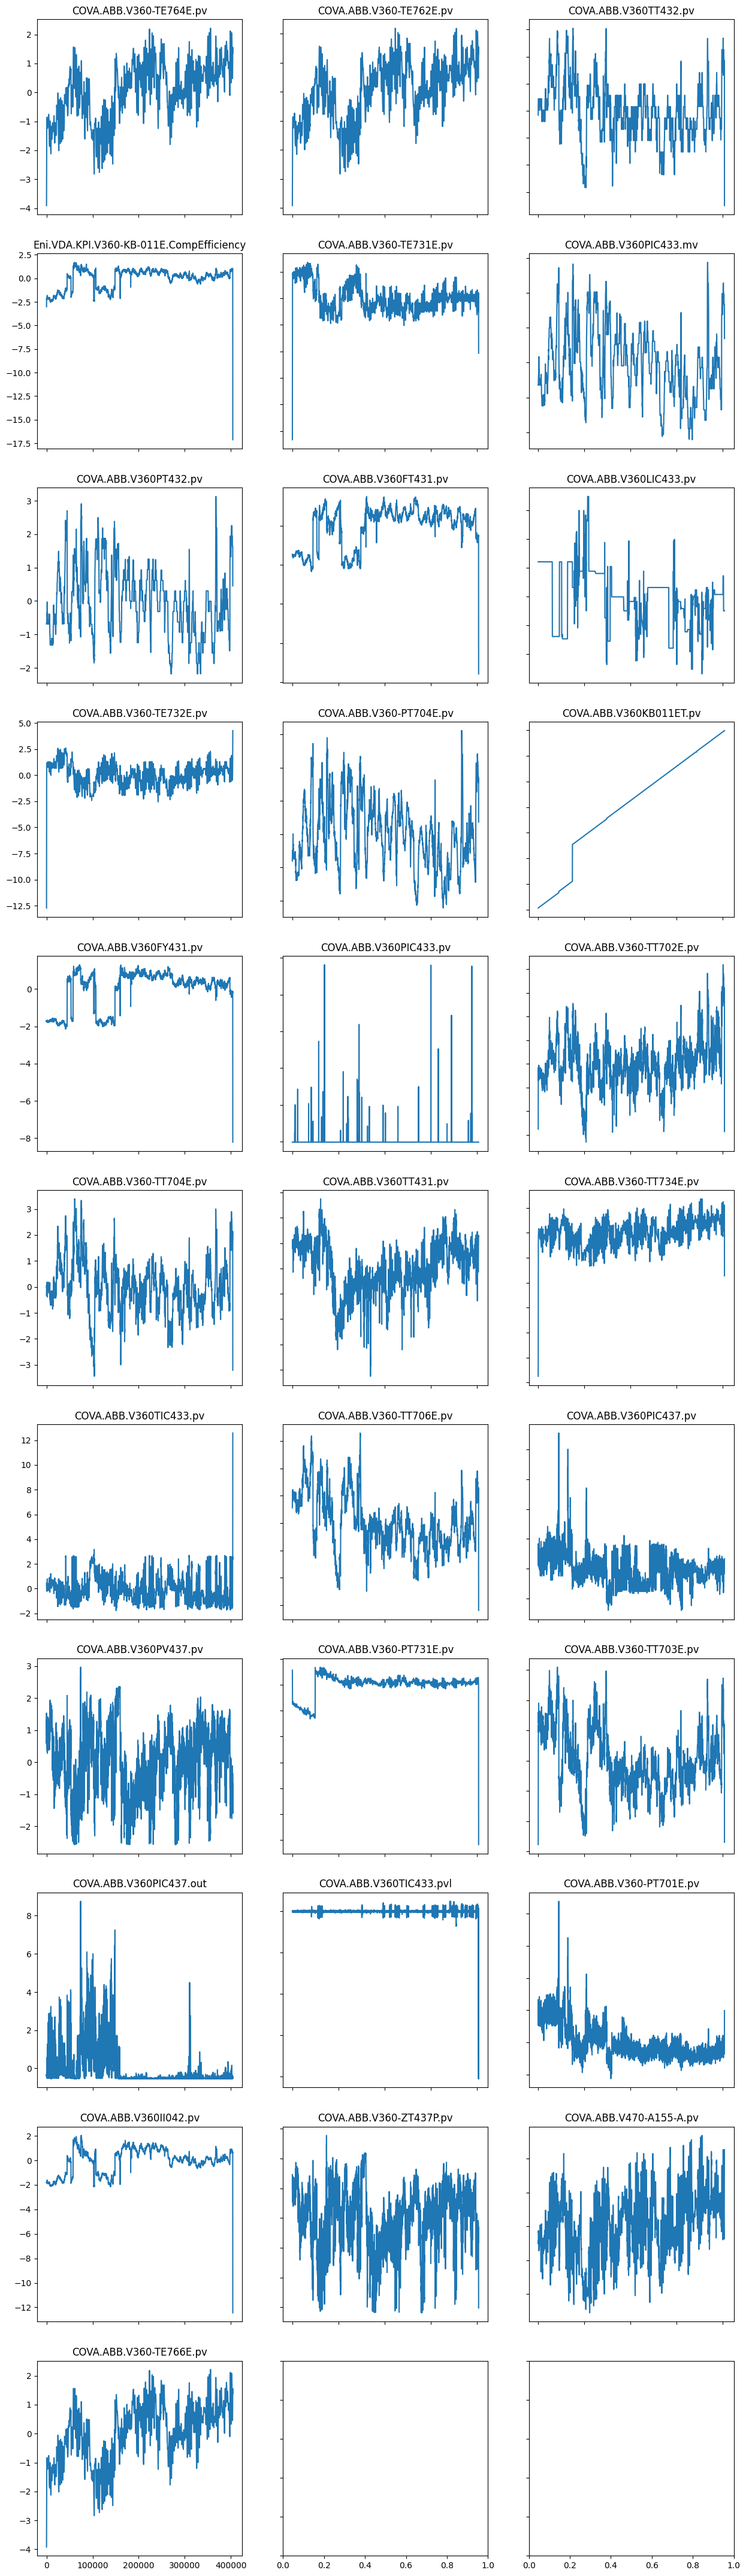

In [136]:
plot_columns_in_grid(scaled_train_df, target_cols)

In [137]:
import gc
gc.collect()

101237

# ***GMM*** - *Gaussian Mixture Model* (Baseline)

As a baseline we are using a **GMM**, namely a a probabilistic model that represents data as a mixture of multiple Gaussian distributions, each defined by its mean and covariance. It is often used for clustering, density estimation, or modeling complex distributions

In [138]:
# Define the parameter grid
param_grid = {'n_components': [2, 4, 8, 16]}

gmm = GaussianMixture(2)

opt = GridSearchCV(
    estimator=gmm,
    param_grid=param_grid,
    cv=3,
    verbose=3,    # Set to 3 for detailed logs
    n_jobs=-1     # Use all available CPU cores
)

gmm.fit(train_df[inputs])


# Print the best parameters
#print(f'Best parameters: {opt.best_params_}')

GaussianMixture(n_components=2)

In [139]:
# This computes the log probability density of the data points in the test set
ldens = gmm.score_samples(test_df[inputs])
signal = pd.Series(index=test_df.index, data=-ldens)

##Find the best threshold

In [140]:
gmm_best_threshold, gmm_best_score = threshold_optimization(signal, test_df['anomaly'], method = 'bayesian')

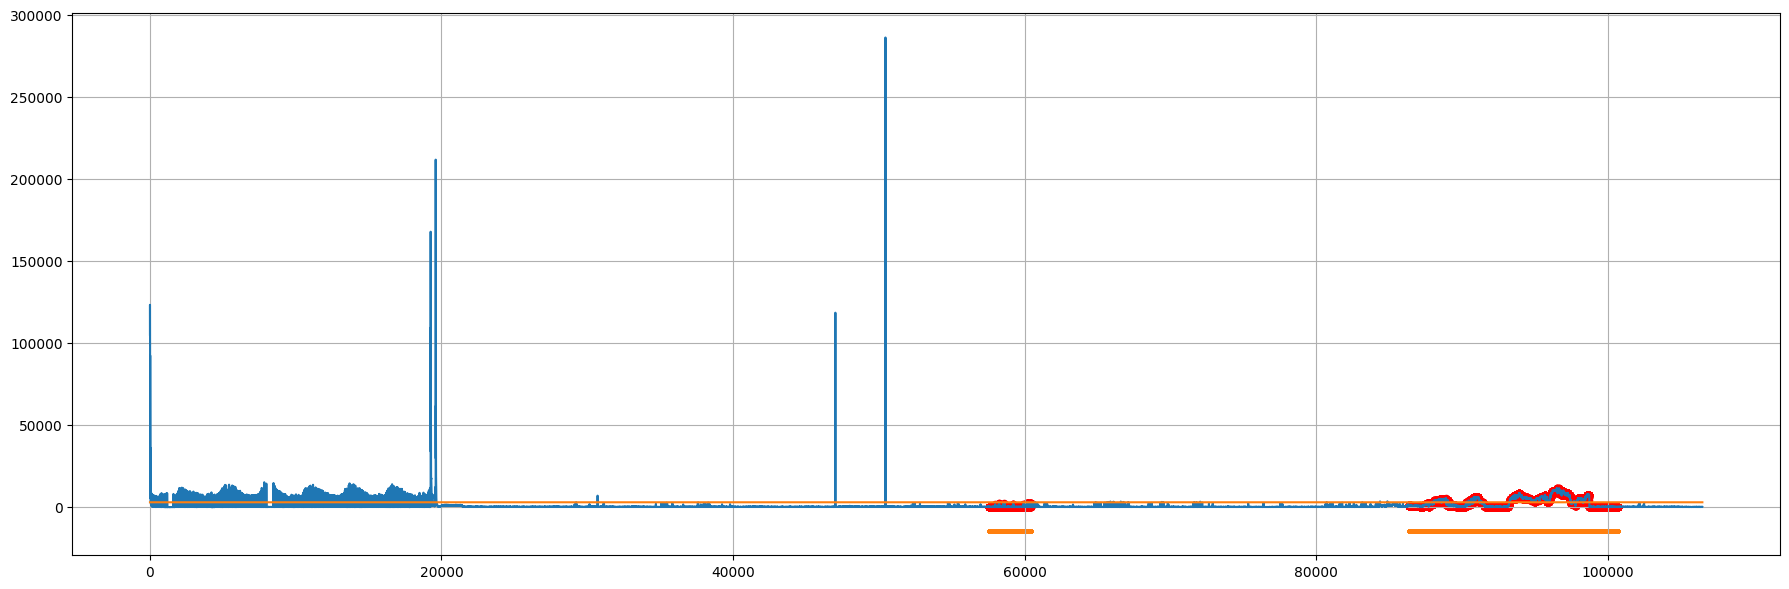

In [141]:
plot_signal(signal, test_df['anomaly'], figsize=figsize, threshold = gmm_best_threshold)

# Deep Learning Models
After the GMM baseline we trained 4 different models (AE, AE_LSTM, VAE and VAE_LSTM)

In [90]:
import gc
gc.collect()

3403

# Settings

In [35]:
batch_size = 32

if torch.cuda.is_available():
  device = torch.device("cuda:0")
else:
  device = torch.device("cpu")

# Define the dataset NOT SLIDED
train_df_dataset = MyDataset(train_df[target_cols], device=device)
test_df_dataset = MyDataset(test_df[target_cols], device=device)

# Define DataLoader
trdata_loader = DataLoader(train_df_dataset, batch_size=batch_size, shuffle=False)
tsdata_loader = DataLoader(test_df_dataset, batch_size=batch_size, shuffle=False)

In [36]:
input_size = len(target_cols)
hidden_size = 128
latent_size = 64
epochs = 5

# Train & Evaluation

In [37]:
true_labels = test_df['anomaly']

## AE

 A simple **Autoencoder** with two main components:

- Encoder: Two linear layers compress the input to a latent space.
- Decoder: Two linear layers reconstruct the input from the latent space.
The model uses **Mean Squared Error** (MSE) for reconstruction loss, and training is handled with the Adam optimizer. It includes early stopping for efficiency, and there are methods for evaluation, prediction, and plotting loss history to monitor performance.

Output: A reconstructed version of the input and a reconstruction error signal with the same size of input.

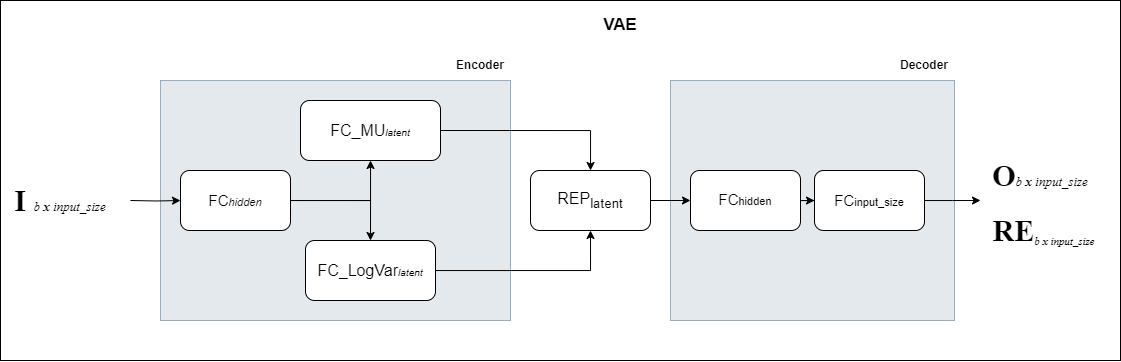

In [38]:
# Define VAE model
ae = AE(input_size, hidden_size, latent_size, device = device).to(device)
_,_ = ae.fit(trdata_loader, num_epochs=epochs, plot_history = False)

Epoch 1/5, Loss: 1533.4852


Epoch 2/5, Loss: 623.5343


Epoch 3/5, Loss: 641.1774


Epoch 4/5, Loss: 620.8565


Epoch 5/5, Loss: 516.7882


In [39]:
ae_preds_test,ae_signal_test = ae.predict(tsdata_loader)

In [40]:
# Convert into dataframe
ae_preds_test = pd.DataFrame(ae_preds_test.cpu().detach().numpy(), columns = target_cols)
ae_signal_test_col = pd.Series(ae_signal_test.mean(dim = 0).cpu().detach().numpy(), index = target_cols)
ae_signal_test_row = pd.Series(ae_signal_test.mean(dim = 1).cpu().detach().numpy())
ae_signal_test = pd.DataFrame(ae_signal_test.cpu().detach().numpy(), columns = target_cols)

### Signal comparison (ground truth vs prediction)

In [ ]:
plot_predicted_on_real_signal(train_df[target_cols], ae_preds_test)

### Plot the signal reconstruction error by feature

In [ ]:
plt.figure(figsize=(15, 15))
plt.barh(target_cols, ae_signal_test_col.sort_values(ascending = True), color='skyblue')
plt.xlabel('Values')
plt.title('Horizontal Bar Plot of the Series')
plt.show()

### Find the best threshold
Threshold optimization using different methos

In [ ]:
# Possible methods = ['bayesian' , 'simple' , 'cross_validation']
ae_best_threshold, ae_best_score = threshold_optimization(ae_signal_test_row, test_df['anomaly'], method = 'bayesian')

### Plot the reconstruction error with anomaly threshold

In [ ]:
plot_signal(ae_signal_test_row, labels =true_labels ,threshold = ae_best_threshold)

## AE_LSTM

An LSTM-based Autoencoder (AE-LSTM) implementation:

- Encoder: Uses an LSTM layer to encode the input sequence into a hidden state, which is then passed through a fully connected layer to map it to the latent space.
- Decoder: Uses another LSTM to decode the latent vector by repeating it for each timestep in the sequence, then a dense layer reconstructs the original input sequence.
The loss function is the Mean Squared Error (MSE) between the input and reconstructed sequence.

Training: the Adam optimizer with early stopping. \
Output: A reconstructed version of the input and a reconstruction error signal with the same size of input.

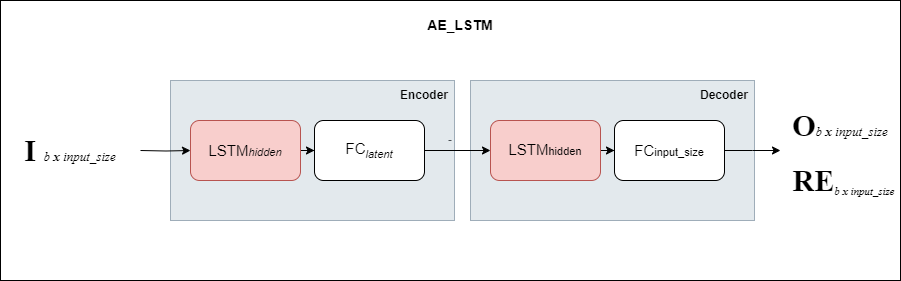

### Train

In [ ]:
# Define VAE model
ae_lstm = AE_LSTM(input_size, hidden_size, latent_size, device = device).to(device)
#best_epoch,_ = optimize_epochs(copy.deepcopy(ae), trdata_loader, valdata_loader, plot_history = True)
#print("best epoch : " , best_epoch)
_,_ = ae_lstm.fit(trdata_loader, num_epochs=epochs, plot_history = False)

Epoch 1/10, Loss: 0.2075


Epoch 2/10, Loss: 0.1553


Epoch 3/10, Loss: 0.1167


Epoch 4/10, Loss: 0.1109


Epoch 5/10, Loss: 0.0995


Epoch 6/10, Loss: 0.1005


Epoch 7/10, Loss: 0.0928


Epoch 8/10, Loss: 0.0902


Epoch 9/10, Loss: 0.0959


Epoch 10/10, Loss: 0.0895


In [ ]:
ae_lstm_preds_test,ae_lstm_signal_test = ae_lstm.predict(tsdata_loader)

In [ ]:
ae_lstm_preds_test = pd.DataFrame(ae_lstm_preds_test.cpu().detach().numpy(), columns = target_cols)
ae_lstm_signal_test_col = pd.Series(ae_lstm_signal_test.mean(dim = 0).cpu().detach().numpy(), index = target_cols)
ae_lstm_signal_test_row = pd.Series(ae_lstm_signal_test.mean(dim = 1).cpu().detach().numpy())
ae_lstm_signal_test = pd.DataFrame(ae_lstm_signal_test.cpu().detach().numpy(), columns = target_cols)

### Signal comparison (ground truth vs prediction)




In [ ]:
plot_predicted_on_real_signal(test_df[target_cols], ae_lstm_preds_test)

### Plot the signal reconstruction error by feature

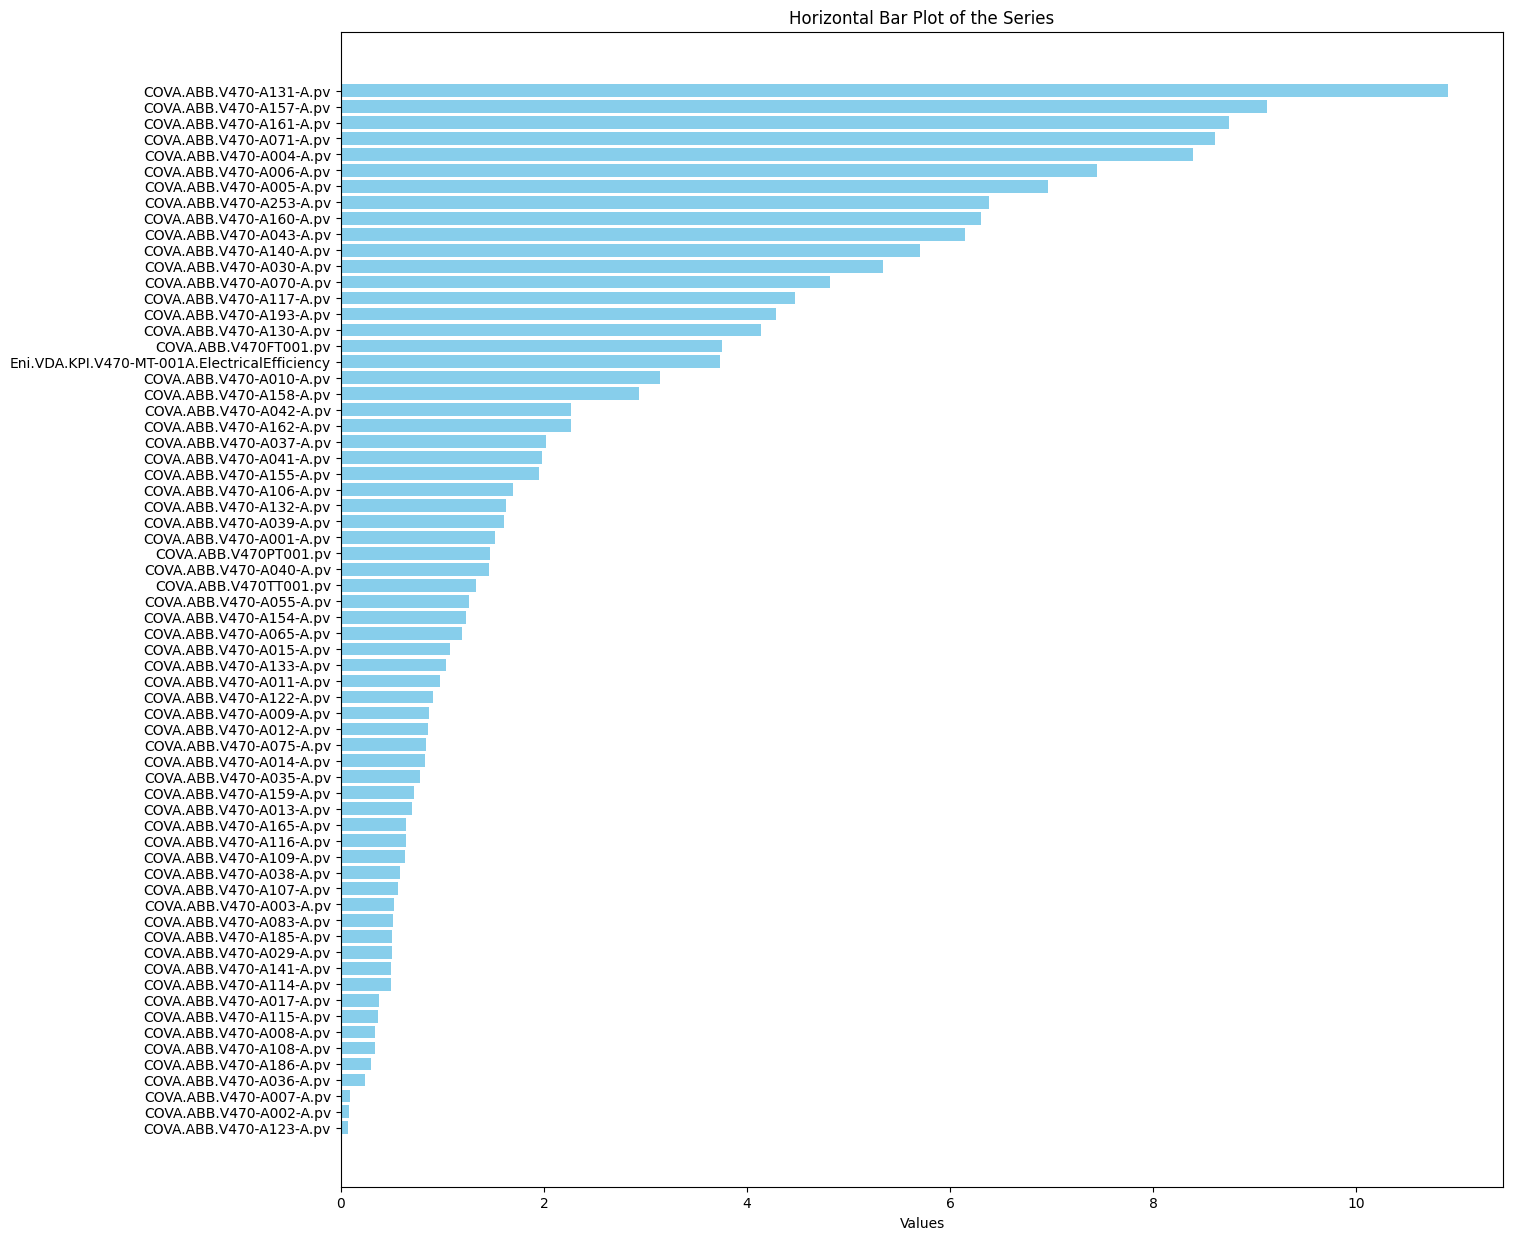

In [ ]:
plt.figure(figsize=(15, 15))
plt.barh(target_cols, ae_lstm_signal_test_col.sort_values(ascending = True), color='skyblue')
plt.xlabel('Values')
plt.title('Horizontal Bar Plot of the Series')
plt.show()

### Find the best threshold
Threshold optimization using different methos

In [ ]:
# Possible methods = ['bayesian' , 'simple' , 'cross_validation']
ae_lstm_best_threshold, ae_lstm_best_score = threshold_optimization(ae_lstm_signal_test_row, test_df['anomaly'], method = 'bayesian')

### Plot the reconstruction error with anomaly threshold

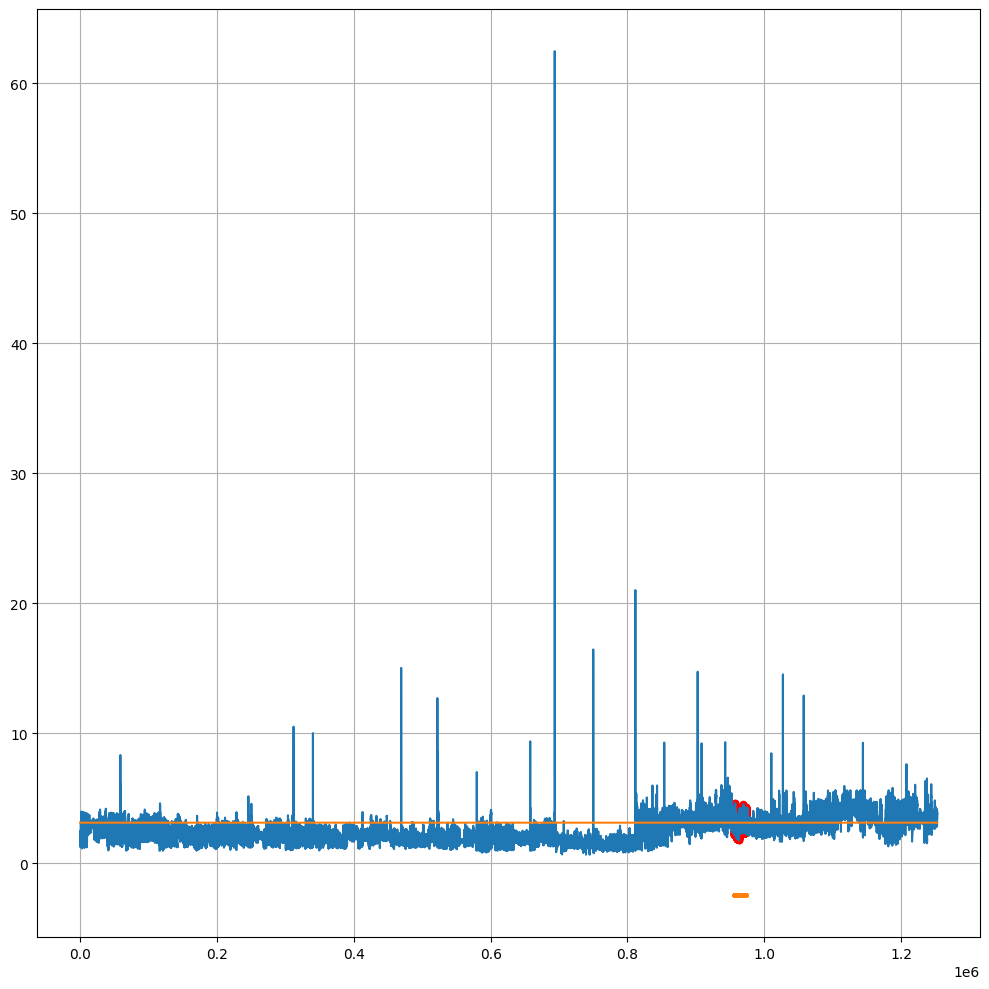

In [ ]:
plot_signal(ae_lstm_signal_test_row, labels =true_labels ,threshold = ae_lstm_best_threshold)

In [ ]:
print(np.mean(ae_signal_test))
print(np.mean(ae_lstm_signal_test))

4.641015
2.486874


## VAE

A Variational Autoencoder (VAE) implementation:

- **Encoder**: The encoder consists of fully connected layers that transform the input into two outputs—mean (mu) and log-variance (logvar)—which are used to generate latent space representations using the reparameterization trick.

- **Decoder**: The decoder reconstructs the original input from the latent space vector using two fully connected layers. The output is normalized using a sigmoid function to ensure values between 0 and 1.

- **Reparameterization**: In the latent space, the model samples from the distribution defined by mu and logvar using the formula: z = mu + std * eps, where eps is a random normal variable.

- **Loss Function**: Combines two components
*   Reconstruction Loss (MSE) between the original input and reconstructed output.
*   KL Divergence between the learned latent distribution and a standard Gaussian distribution to regularize the latent space.

- **Training**: The model is trained using the Adam optimizer with early stopping and tracks loss through epochs. The fit method handles training and optional validation, while also allowing the option to visualize training and validation loss over time.

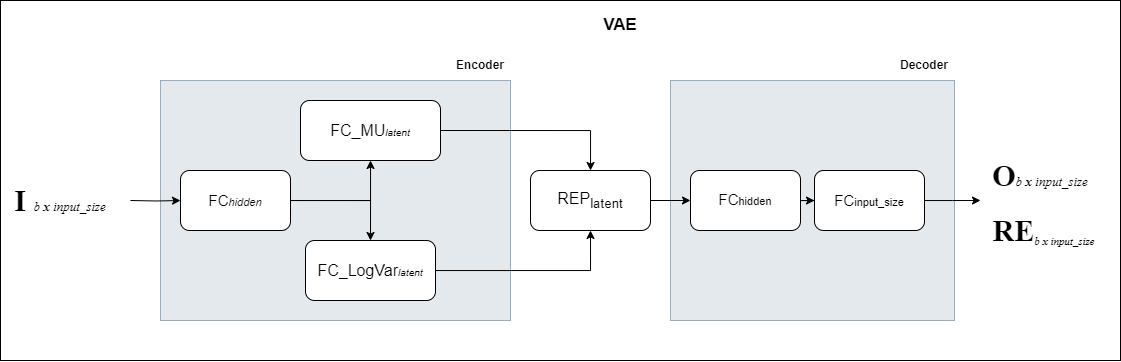

In [ ]:
vae = VAE(input_size, hidden_size, latent_size, device = device).to(device)
_,_ = vae.fit(trdata_loader, num_epochs=epochs, plot_history = False)

Epoch 1/10, Loss: 0.3019
Epoch 2/10, Loss: 7460325.6679
Epoch 3/10, Loss: 766309283471606100787200.0000
Epoch 4/10, Loss: nan
Early stopping!


In [ ]:
vae_preds_test,vae_signal_test = vae.predict(tsdata_loader)

In [ ]:
# Convert into dataframe
vae_preds_test = pd.DataFrame(vae_preds_test.cpu().detach().numpy(), columns = target_cols)
vae_signal_test_col = pd.Series(vae_signal_test.mean(dim = 0).cpu().detach().numpy(), index = target_cols)
vae_signal_test_row = pd.Series(vae_signal_test.mean(dim = 1).cpu().detach().numpy())
vae_signal_test = pd.DataFrame(vae_signal_test.cpu().detach().numpy(), columns = target_cols)

### Signal comparison (ground truth vs prediction)



In [ ]:
plot_predicted_on_real_signal(test_df[target_cols], vae_preds_test)

### Plot the signal reconstruction error by feature

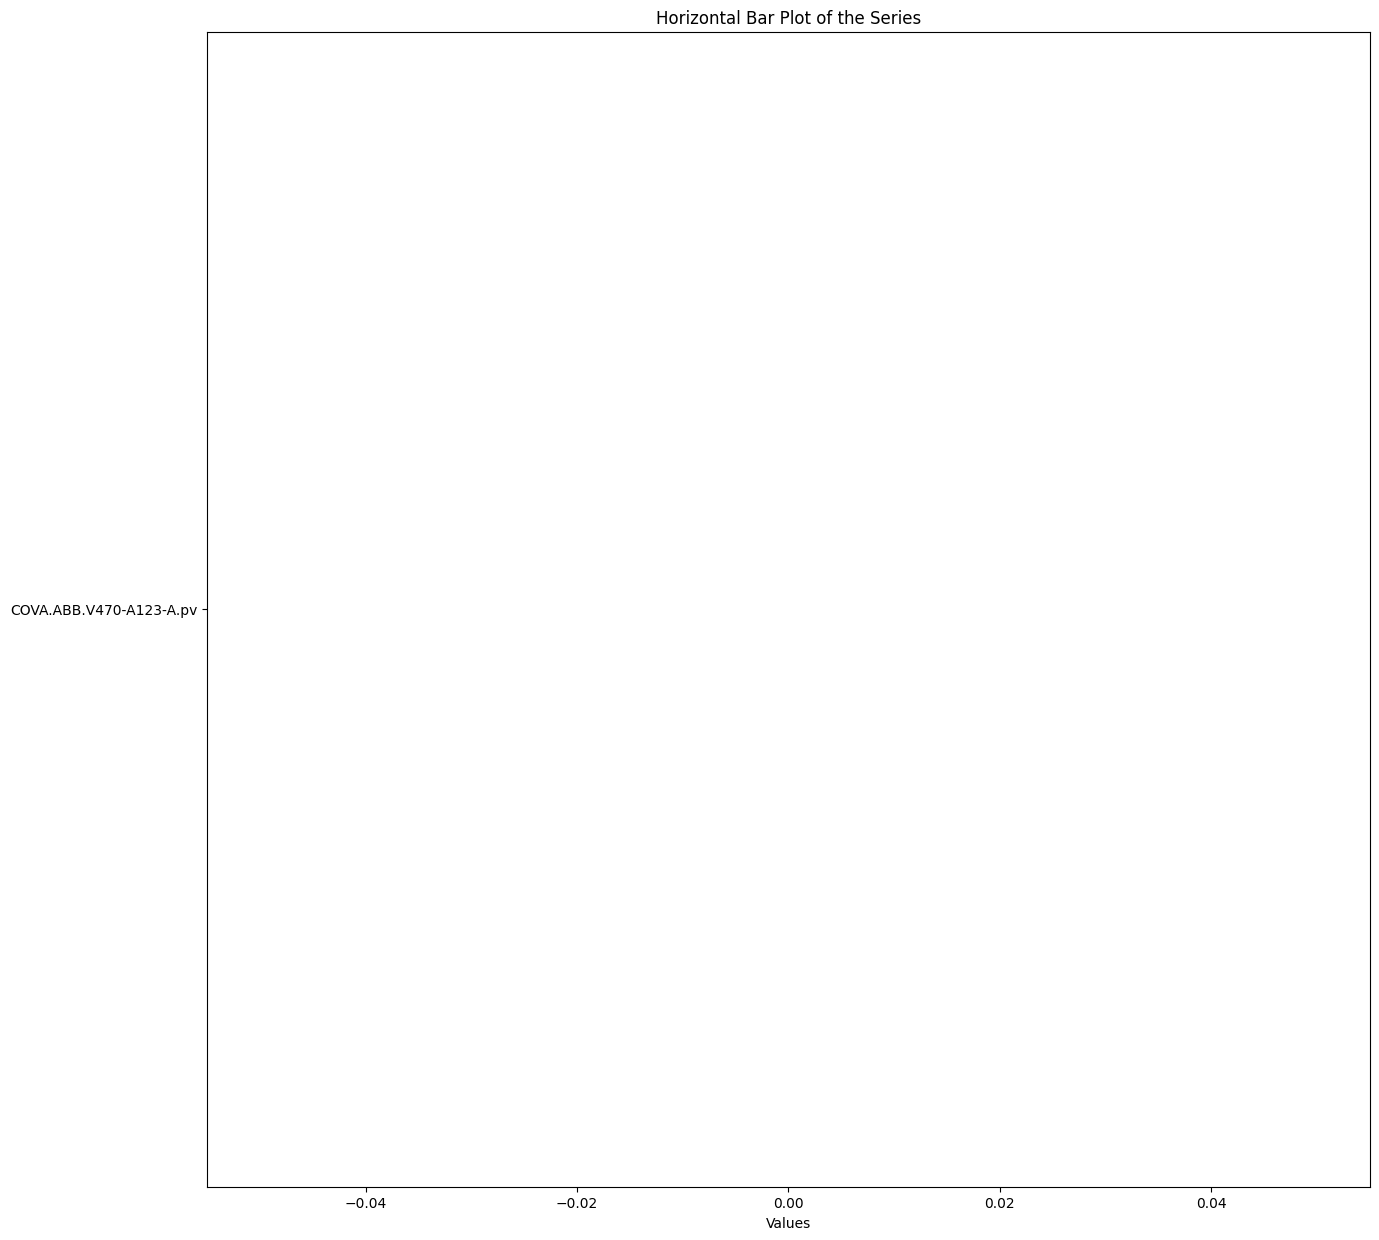

In [ ]:
plt.figure(figsize=(15, 15))
plt.barh(target_cols, vae_signal_test_col.sort_values(ascending = True), color='skyblue')
plt.xlabel('Values')
plt.title('Horizontal Bar Plot of the Series')
plt.show()

### Find the best threshold
Threshold optimization using different methos

In [ ]:
# Possible methods = ['bayesian' , 'simple' , 'cross_validation']
vae_best_threshold, vae_best_score = threshold_optimization(vae_signal_test_row, test_df['anomaly'], method = 'bayesian')

/usr/local/lib/python3.10/dist-packages/skopt/space/space.py:116: UserWarning: Dimension Real(low=nan, high=nan, prior='uniform', transform='identity') was inferred to Real(low=nan, high=nan, prior='uniform', transform='identity'). In upcoming versions of scikit-optimize, it will be inferred to Real(low=nan, high=nan, prior='uniform', transform='identity'). See the documentation of the check_dimension function for the upcoming API.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/skopt/space/space.py:116: UserWarning: Dimension Real(low=nan, high=nan, prior='uniform', transform='normalize') was inferred to Real(low=nan, high=nan, prior='uniform', transform='normalize'). In upcoming versions of scikit-optimize, it will be inferred to Real(low=nan, high=nan, prior='uniform', transform='normalize'). See the documentation of the check_dimension function for the upcoming API.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/skopt/space/space.py:116: UserWarning: Dimension Re

ValueError: Point ([nan]) is not within the bounds of the space ([(nan, nan)]).

### Plot the reconstruction error with anomaly threshold

In [ ]:
plot_signal(vae_signal_test_row, labels =true_labels ,threshold = vae_best_threshold)

## VAE_LSTM

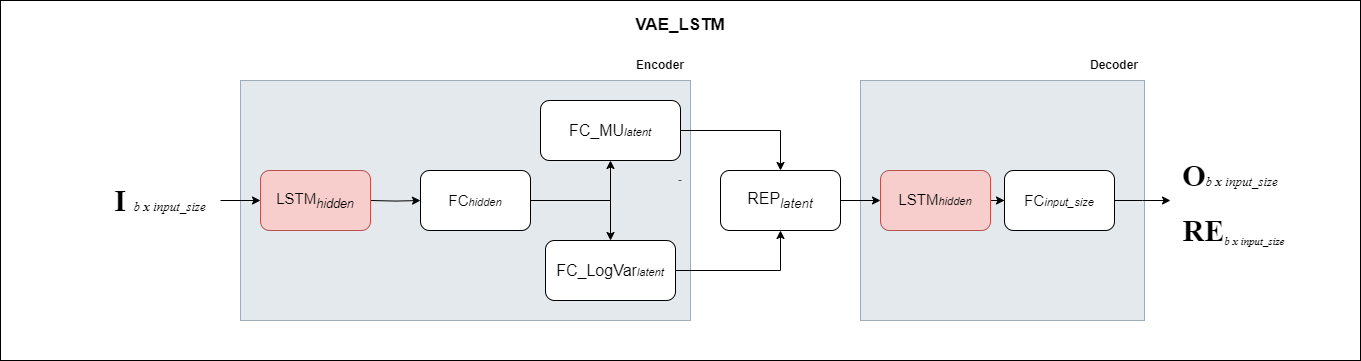

In [ ]:
vae_lstm = VAE_LSTM(input_size, hidden_size, latent_size, device = device).to(device)
_,_ = vae_lstm.fit(trdata_loader, num_epochs=epochs, plot_history = False)

In [ ]:
vae_lstm_preds_test,vae_lstm_signal_test = vae_lstm.predict(tsdata_loader)

In [ ]:
# Convert into dataframe
vae_lstm_preds_test = pd.DataFrame(vae_lstm_preds_test.cpu().detach().numpy(), columns = target_cols)
vae_lstm_signal_test_col = pd.Series(vae_lstm_signal_test.mean(dim = 0).cpu().detach().numpy(), index = target_cols)
vae_lstm_signal_test_row = pd.Series(vae_lstm_signal_test.mean(dim = 1).cpu().detach().numpy())
vae_lstm_signal_test = pd.DataFrame(vae_lstm_signal_test.cpu().detach().numpy(), columns = target_cols)

### Signal comparison (ground truth vs prediction)

In [ ]:
plot_predicted_on_real_signal(test_df[target_cols], vae_lstm_preds_test)

### Plot the signal reconstruction error by feature

In [ ]:
plt.figure(figsize=(15, 15))
plt.barh(target_cols, vae_lstm_signal_test_col.sort_values(ascending = True), color='skyblue')
plt.xlabel('Values')
plt.title('Horizontal Bar Plot of the Series')
plt.show()

### Find the best threshold
Threshold optimization using different methos

In [ ]:
# Possible methods = ['bayesian' , 'simple' , 'cross_validation']
vae_lstm_best_threshold, vae_lstm_best_score = threshold_optimization(vae_lstm_signal_test_row, test_df['anomaly'], method = 'bayesian')

### Plot the reconstruction error with anomaly threshold

In [ ]:
plot_signal(vae_lstm_signal_test_row, labels =true_labels ,threshold = vae_lstm_best_threshold)

# FInal Comparison

AE vs AE_LSTM

In [ ]:
print(f'The mean of MSE for AE is: {np.mean(ae_signal_test)}')
print(f'The mean of MSE for AE_LSTM is: {np.mean(ae_lstm_signal_test)}')

In [ ]:
labels = test_df['anomaly']

plt.plot(ae_signal_test_row, label = "AE")
plt.plot(ae_lstm_signal_test_row, label = "AE-LSTM")

s = 4
nonzero = ae_signal_test_row.index[labels != 0]
smin, smax = np.min(ae_signal_test_row), np.max(ae_signal_test_row)
lvl = smin - 0.05 * (smax - smin)
if plt is not None:
      plt.scatter(nonzero, np.ones(len(nonzero)) * lvl, s=s, color='tab:red', label='labels')
else:
      plt.scatter(nonzero, np.ones(len(nonzero)) * lvl, s=s, color='tab:red', label='labels')
plt.legend()
plt.show()

VAE vs VAE_LSTM

In [ ]:
print(f'The mean of the reconstruction error + KL divergence for VAE is {np.mean(vae_signal_test)}')
print(f'The mean of the reconstruction error + KL divergence for VAE_LSTM is {np.mean(vae_lstm_signal_test)}')

In [ ]:
labels = test_df['anomaly']

plt.plot(vae_signal_test_row, label = "AE")
plt.plot(vae_lstm_signal_test_row, label = "AE-LSTM")

s = 4
nonzero = vae_signal_test_row.index[labels != 0]
smin, smax = np.min(vae_signal_test_row), np.max(vae_signal_test_row)
lvl = smin - 0.05 * (smax - smin)
if plt is not None:
      plt.scatter(nonzero, np.ones(len(nonzero)) * lvl, s=s, color='tab:red', label='labels')
else:
      plt.scatter(nonzero, np.ones(len(nonzero)) * lvl, s=s, color='tab:red', label='labels')
plt.legend()
plt.show()

F1 in comparison

In [ ]:
score = pd.DataFrame(index = ['GMM', 'AE', 'AE_LSTM', 'VAE', 'VAE_LSTM'], columns = ['F1'])
score.loc['AE'] = ae_best_score
score.loc['AE_LSTM'] = ae_lstm_best_score
score.loc['VAE'] = vae_best_score
score.loc['VAE_LSTM'] = vae_lstm_best_score
score.loc['GMM'] = gmm_best_score

In [ ]:
score

In [ ]:
# Plotting
plt.figure(figsize=(10, 6))
bars = plt.bar(score.index, score['F1'], color='skyblue', edgecolor='black', linewidth=1.2)

# Adding data labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.01, round(yval, 3), ha='center', va='bottom')

# Customizing the plot
plt.title('F1 Scores by Models', fontsize=16, fontweight='bold')
plt.xlabel('Models', fontsize=14)
plt.ylabel('F1 Score', fontsize=14)
plt.ylim(0, 1.1)  # Assuming F1 scores are between 0 and 1
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Display plot
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#Conclusion
All the 5 models performed very well on the test set. As we can see from the bar plot the baseline obtained the best results, but in our analysis this occurs because of a mislabeled anomaly in the test set. Indeed, we can see from the signal plots that in correspondece of the error-peaks of the 4 DL models there is a spike in the signal similar to anomalies.
The VAE_LSTM is the one that perform the best on this dataset, this could be related to the high degree of variability in data. The LSTM module handles better sequential dependencies and long-range temporal patterns.